In [1]:
# Install first:
# pip install -U langgraph

from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# -----------------------------
# Shared state between agents
# -----------------------------
class AgentState(TypedDict):
    request: str
    traffic_result: str
    final_decision: str


# -----------------------------
# Agent 1: Navigation Agent
# -----------------------------
def navigation_agent(state: AgentState):
    print("\n[NAVIGATION AGENT]")
    print("Sending request to Traffic Agent:")
    print(state["request"])

    return state


# -----------------------------
# Agent 2: Traffic Agent
# -----------------------------
def traffic_agent(state: AgentState):
    print("\n[TRAFFIC AGENT]")
    print("Received request from Navigation Agent")

    # Simulated tool/result
    traffic_result = "Heavy traffic detected on Route A. Route B is better."

    print("Sending response:")
    print(traffic_result)

    return {
        **state,
        "traffic_result": traffic_result
    }


# -----------------------------
# Navigation Agent makes decision
# -----------------------------
def navigation_decision_agent(state: AgentState):
    print("\n[NAVIGATION AGENT]")
    print("Received Traffic Agent response:")
    print(state["traffic_result"])

    if "Route B" in state["traffic_result"]:
        decision = "Use Route B"
    else:
        decision = "Use Route A"

    print("Final decision:", decision)

    return {
        **state,
        "final_decision": decision
    }


# -----------------------------
# Build Agent Graph
# -----------------------------
workflow = StateGraph(AgentState)

workflow.add_node("navigation_agent", navigation_agent)
workflow.add_node("traffic_agent", traffic_agent)
workflow.add_node("navigation_decision", navigation_decision_agent)

workflow.add_edge(START, "navigation_agent")
workflow.add_edge("navigation_agent", "traffic_agent")
workflow.add_edge("traffic_agent", "navigation_decision")
workflow.add_edge("navigation_decision", END)

app = workflow.compile()


# -----------------------------
# Run
# -----------------------------
result = app.invoke({
    "request": "Check traffic on Route A",
    "traffic_result": "",
    "final_decision": ""
})

print("\nFINAL RESULT:")
print(result["final_decision"])


[NAVIGATION AGENT]
Sending request to Traffic Agent:
Check traffic on Route A

[TRAFFIC AGENT]
Received request from Navigation Agent
Sending response:
Heavy traffic detected on Route A. Route B is better.

[NAVIGATION AGENT]
Received Traffic Agent response:
Heavy traffic detected on Route A. Route B is better.
Final decision: Use Route B

FINAL RESULT:
Use Route B


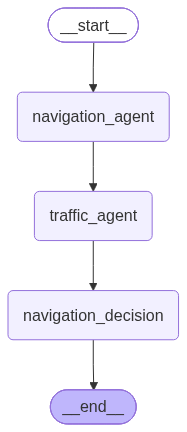

In [2]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))